In [11]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Callable, Tuple, List

$$
f(x) = \sum_{i=1}^{n} x_i^2
$$


In [12]:
def sphere(x):
    return -np.sum(np.square(x))

$$
f(x) = 10 n + \sum_{i=1}^{n} \left[ x_i^2 - A \cos(2 \pi x_i) \right]
$$


In [13]:
def rastrigin(x):
    return -(10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x)))

$$
f(x) = -a \, \exp\left(-b \sqrt{\frac{1}{n} \sum_{i=1}^{n} x_i^2}\right)
      - \exp\left(\frac{1}{n} \sum_{i=1}^{n} \cos(c x_i)\right)
      + a + e
$$


In [14]:
def ackley(x):
    a, b, c = 20, 0.2, 2 * np.pi
    n = len(x)
    term1 = -a * np.exp(-b * np.sqrt(np.sum(x**2) / n))
    term2 = -np.exp(np.sum(np.cos(c * x)) / n)
    return -(term1 + term2 + a + np.e)

$$
f(x) = 1 + \frac{1}{4000} \sum_{i=1}^{n} x_i^2 - \prod_{i=1}^{n} \cos\left( \frac{x_i}{\sqrt{i}} \right)
$$


In [15]:
def griewank(x):
    part1 = np.sum(x**2) / 4000
    part2 = np.prod(np.cos(x / np.sqrt(np.arange(1, len(x) + 1))))
    return -(part1 - part2 + 1)

$$
f(x) = 418.9829n - \sum_{i=1}^{n} x_i \sin\left(\sqrt{|x_i|}\right)
$$


In [16]:
def schwefel(x):
    return -(418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x)))))

$$
f(x) = \sum_{i=1}^{n-1} \left[ 100 (x_{i+1} - x_i^2)^2 + (x_i - 1)^2 \right]
$$


In [17]:
def rosenbrock(x):
    return -np.sum(100 * (x[1:] - x[:-1]**2)**2 + (1 - x[:-1])**2)

$$
f(x) = - \sum_{i=1}^{n} \sin(x_i) \left[ \sin\left( \frac{i x_i^2}{\pi} \right) \right]^{2m}
$$


In [18]:
def michalewicz(x):
    m = 10
    i = np.arange(1, len(x)+1)
    return -np.sum(np.sin(x) * (np.sin(i * x**2 / np.pi))**(2*m))

$$
f(x) = \sum_{i=1}^{n} x_i^2 + \left( \frac{1}{2} \sum_{i=1}^{n} i x_i \right)^2 + \left( \frac{1}{2} \sum_{i=1}^{n} i x_i \right)^4
$$



In [19]:
def zakharov(x):
    term1 = np.sum(x**2)
    term2 = (0.5 * np.arange(1, len(x)+1) * x)**2
    term3 = (0.5 * np.arange(1, len(x)+1) * x)**4
    return -(term1 + term2 + term3)

In [20]:
@dataclass
class GAConfig:
    pop_size: int = 100
    generations: int = 100
    crossover_prob: float = 0.9
    mutation_prob: float = 0.1
    mutation_sigma: float = 0.5
    tournament_k: int = 3
    bounds: Tuple[float, float] = (-5.12, 5.12)
    enable_crossover: bool = True
    enable_mutation: bool = True
    dim: int = 1


In [32]:
def init_population(config: GAConfig):
    low, high = config.bounds
    return np.random.uniform(low, high, size=(config.pop_size, config.dim))

In [34]:
def tournament_select(pop: np.ndarray, fitnesses: np.ndarray, k: int) -> np.ndarray:
    idx = np.random.choice(len(pop), size=k, replace=False)
    return pop[idx[np.argmax(fitnesses[idx])]]

In [35]:
def arithmetic_crossover(a: np.ndarray, b: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    alpha = np.random.rand()
    return alpha*a + (1-alpha)*b, alpha*b + (1-alpha)*a


In [36]:
def mutate(x: np.ndarray, sigma: float, bounds: Tuple[float, float]) -> np.ndarray:
    x_new = x + np.random.randn(*x.shape) * sigma
    low, high = bounds
    return np.clip(x_new, low, high)


In [25]:
def run_ga_once(config: GAConfig, fitness_func: Callable[[np.ndarray], float]) -> List[float]:
    pop = init_population(config)
    best_per_gen = []
    for _ in range(config.generations):
        fitnesses = np.array([fitness_func(np.atleast_1d(ind)) for ind in pop])
        best_per_gen.append(np.max(fitnesses))
        new_pop = []
        while len(new_pop) < config.pop_size:
            p1 = tournament_select(pop, fitnesses, config.tournament_k)
            p2 = tournament_select(pop, fitnesses, config.tournament_k)
            if config.enable_crossover and np.random.rand() < config.crossover_prob:
                c1, c2 = arithmetic_crossover(p1, p2)
            else:
                c1, c2 = p1.copy(), p2.copy()
            if config.enable_mutation and np.random.rand() < config.mutation_prob:
                c1 = mutate(c1, config.mutation_sigma, config.bounds)
            if config.enable_mutation and np.random.rand() < config.mutation_prob:
                c2 = mutate(c2, config.mutation_sigma, config.bounds)
            new_pop.extend([c1, c2])
        pop = np.array(new_pop[:config.pop_size])
    fitnesses = np.array([fitness_func(np.atleast_1d(ind)) for ind in pop])
    best_per_gen.append(np.max(fitnesses))
    return best_per_gen


In [37]:
def average_runs(config: GAConfig, func: Callable, repeats=20):
    all_runs = []
    for i in range(repeats):
        np.random.seed(i + 123)
        best = run_ga_once(config, func)
        all_runs.append(best)
    return np.mean(all_runs, axis=0)

In [27]:
functions = {
    "sphere": sphere,
    "rastrigin": rastrigin,
    "ackley": ackley,
    "griewank": griewank,
    "schwefel": schwefel,
    "rosenbrock": rosenbrock,
    "michalewicz": michalewicz,
    "zakharov": zakharov
}

In [48]:
current_function = "griewank"  
fitness_fn = functions[current_function]

In [49]:
generations = 25
repeats = 20

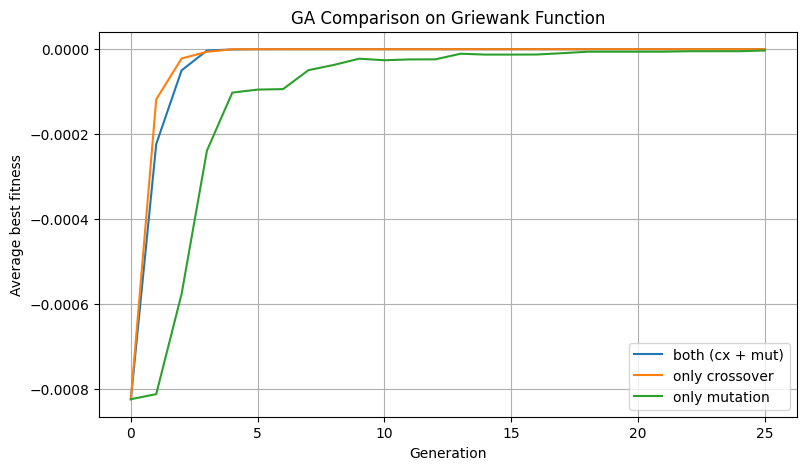

In [50]:
config_both = GAConfig(generations=generations, enable_crossover=True, enable_mutation=True)
config_only_cx = GAConfig(generations=generations, enable_crossover=True, enable_mutation=False, mutation_prob=0.0)
config_only_mut = GAConfig(generations=generations, enable_crossover=False, enable_mutation=True, crossover_prob=0.0, mutation_prob=0.2)

# Run all three
mean_both = average_runs(config_both, fitness_fn, repeats)
mean_cx = average_runs(config_only_cx, fitness_fn, repeats)
mean_mut = average_runs(config_only_mut, fitness_fn, repeats)

# Plot
gens = list(range(generations+1))
plt.figure(figsize=(9,5))
plt.plot(gens, mean_both, label='both (cx + mut)')
plt.plot(gens, mean_cx, label='only crossover')
plt.plot(gens, mean_mut, label='only mutation')
plt.xlabel('Generation')
plt.ylabel('Average best fitness')
plt.title(f'GA Comparison on {current_function.capitalize()} Function')
plt.legend()
plt.grid(True)
plt.show()
